# Analyse Human Evaluation Answers

In [34]:
import json
import difflib
import numpy as np
import pandas as pd
import concurrent.futures
import plotly.express as px
from scipy.stats import rankdata
from scipy.stats import wilcoxon

In [2]:
with open("evaluations.json", "r") as f:
    data = json.load(f)

evaluations = pd.DataFrame(data)

evaluations['group'] = evaluations['mode'].apply(lambda x: 'With Hints' if x == 'hints' else 'Without Hints')
evaluations = evaluations.drop(columns=['mode', 'consent', 'id', 'endTime', 'startTime'])
evaluations.head()

,codeText,timeInSeconds,group
0,"def max_happiness(N, friday_matrix, saturday_m...",542,With Hints
1,from itertools import permutations\n\ndef max_...,464,Without Hints
2,"def max_happiness(N, friday_matrix, saturday_m...",594,With Hints
3,"def max_happiness(N, friday_matrix, saturday_m...",202,Without Hints
4,"def max_happiness(N, friday, saturday):\n m...",1458,Without Hints


In [3]:
generated_solution = """def max_happiness(N, friday_matrix, saturday_matrix):
    def calculate_happiness(friday_perm, saturday_perm):
        total_happiness = 0
        for i in range(N // 2):
            total_happiness += friday_matrix[i][friday_perm[i]]
            total_happiness += saturday_matrix[i][saturday_perm[i]]
        return total_happiness
    from itertools import permutations
    friday_perms = list(permutations(range(N // 2)))
    saturday_perms = list(permutations(range(N // 2)))
    max_happiness = 0
    for friday_perm in friday_perms:
        for saturday_perm in saturday_perms:
            current_happiness = calculate_happiness(friday_perm, saturday_perm)
            if current_happiness > max_happiness:
                max_happiness = current_happiness
    return max_happiness"""

In [4]:
test_solution = """def max_happiness(N, friday_matrix, saturday_matrix):
    def calculate_happiness(friday_perm, saturday_perm):
        total_happiness = 50
        for i in range(N // 2):
            total_happiness += friday_matrix[i][friday_perm[i]][2]
            total_happiness += saturday_matrix[i][saturday_perm[i]]
        return total_happiness
    from itertools import permutations
    friday_perms = list(permutations(range(N // 2)))
    saturday_perms = list(permutations(range(N // 2)))
    max_happiness = 0
    for friday_perm in friday_perms:
        for saturday_perm in saturday_perms:
            current_happiness = calculate_happiness(friday_perm, saturday_perm)
            if current_happiness > max_happiness:
                max_happiness = current_happiness
    return wnother_max_happiness"""

# How many lines changed?
We also need to compute the survival rate for each response:

In [5]:
def token_diff_count(base_code, compare_code):
    # Tokenize by splitting on whitespace
    base_tokens = base_code.split()
    compare_tokens = compare_code.split()
    
    # Compare tokens
    diff = list(difflib.ndiff(base_tokens, compare_tokens))
    changes = [d for d in diff if d.startswith('+ ') or d.startswith('- ')]
    return int(len(changes)/2)
token_diff_count(generated_solution, evaluations['codeText'][15])

19

In [6]:
evaluations['changed_lines'] = evaluations["codeText"].apply(lambda x: token_diff_count(generated_solution, x))
evaluations.head()

,codeText,timeInSeconds,group,changed_lines
0,"def max_happiness(N, friday_matrix, saturday_m...",542,With Hints,0
1,from itertools import permutations\n\ndef max_...,464,Without Hints,32
2,"def max_happiness(N, friday_matrix, saturday_m...",594,With Hints,0
3,"def max_happiness(N, friday_matrix, saturday_m...",202,Without Hints,3
4,"def max_happiness(N, friday, saturday):\n m...",1458,Without Hints,81


# Test Solutions
We also need to compute the accuracy for each response:

In [7]:
def test_minimum_case(max_happiness):
    N = 2
    friday = [
        [10, 20],
        [30, 40]
    ]
    saturday = [
        [15, 25],
        [35, 45]
    ]
    # Optimal: person 0 on Fri club 1 (20), person 1 on Sat club 1 (45)
    # Total = 20 + 45 = 65
    assert max_happiness(N, friday, saturday) == 65

def test_all_zero_preferences(max_happiness):
    N = 4
    friday = [
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]
    ]
    saturday = [
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]
    ]
    assert max_happiness(N, friday, saturday) == 0

def test_uniform_preferences(max_happiness):
    N = 4
    friday = [[5]*N for _ in range(N)]
    saturday = [[5]*N for _ in range(N)]
    # Any combination should give 4*5 = 20
    assert max_happiness(N, friday, saturday) == 20

def test_regular_case(max_happiness):
    N = 4
    friday = [
        [9, 2, 7, 8],
        [6, 4, 3, 7],
        [5, 8, 1, 8],
        [7, 6, 9, 4]
    ]
    saturday = [
        [6, 4, 7, 1],
        [2, 5, 8, 3],
        [7, 9, 4, 2],
        [1, 3, 6, 5]
    ]
    result = max_happiness(N, friday, saturday)
    assert isinstance(result, int)
    assert result >= 0  # just a sanity check

def test_highly_contrasted_preferences(max_happiness):
    N = 4
    friday = [
        [100, 0, 0, 0],
        [0, 100, 0, 0],
        [0, 0, 100, 0],
        [0, 0, 0, 100]
    ]
    saturday = [
        [0, 100, 0, 0],
        [0, 0, 100, 0],
        [0, 0, 0, 100],
        [100, 0, 0, 0]
    ]
    # Friday: choose first 2 on Fri with perfect match
    # Saturday: last 2 on Sat with perfect match
    assert max_happiness(N, friday, saturday) == 400

def test_medium_case_8(max_happiness):
    import random
    random.seed(0)
    N = 8
    friday = [[random.randint(1, 10) for _ in range(N)] for _ in range(N)]
    saturday = [[random.randint(1, 10) for _ in range(N)] for _ in range(N)]
    result = max_happiness(N, friday, saturday)
    assert isinstance(result, int)
    assert result >= 0
    
def test_constraint_violation_odd_N(max_happiness):
    N = 3  # Not even — violates problem constraint
    friday = [[1]*N for _ in range(N)]
    saturday = [[1]*N for _ in range(N)]
    assert max_happiness(N, friday, saturday) == 0

def test_friday_much_better_than_saturday(max_happiness):
    N = 4
    friday = [
        [100, 90, 80, 70],
        [60, 50, 40, 30],
        [20, 10, 5, 3],
        [2, 1, 0, 0]
    ]
    saturday = [
        [1, 1, 1, 1],
        [1, 1, 1, 1],
        [1, 1, 1, 1],
        [1, 1, 1, 1]
    ]
    result = max_happiness(N, friday, saturday)
    assert result > 4  # Minimum possible (if all Saturday) would be 4
    
def test_multiple_optimal_solutions(max_happiness):
    N = 2
    friday = [
        [10, 0],
        [0, 10]
    ]
    saturday = [
        [0, 10],
        [10, 0]
    ]
    # Two possible equally good ways to assign 1 to Friday and 1 to Saturday
    assert max_happiness(N, friday, saturday) == 20

In [8]:
def get_passed_tests(max_happiness_solution):
    tests = [
        test_minimum_case,
        test_all_zero_preferences,
        test_uniform_preferences,
        test_regular_case,
        test_highly_contrasted_preferences,
        test_medium_case_8,
        test_constraint_violation_odd_N,
        test_friday_much_better_than_saturday,
        test_multiple_optimal_solutions
    ]

    passed = 0
    failed = 0

    for test in tests:
        try:
            test(max_happiness_solution)
            passed += 1
        except AssertionError as e:
            failed += 1
        except Exception as e:
            failed += 1

    return passed

In [9]:
def evaluate_code_string(code_str):
    local_env = {}
    try:
        exec(code_str, {}, local_env)
        solution_func = local_env.get("max_happiness")
        if not callable(solution_func):
            return 0
        return get_passed_tests(solution_func)
    except Exception:
        return 0

evaluate_code_string(generated_solution)

5

In [10]:
evaluations["passed_tests"] = 0

In [24]:
for index, row in evaluations.iterrows():
    if index != 15 and index != 21:
        evaluations.loc[index, "passed_tests"] = evaluate_code_string(row['codeText'])

In [15]:
evaluations.head()

,codeText,timeInSeconds,group,changed_lines,passed_tests
0,"def max_happiness(N, friday_matrix, saturday_m...",542,With Hints,0,5
1,from itertools import permutations\n\ndef max_...,464,Without Hints,32,0
2,"def max_happiness(N, friday_matrix, saturday_m...",594,With Hints,0,5
3,"def max_happiness(N, friday_matrix, saturday_m...",202,Without Hints,3,6
4,"def max_happiness(N, friday, saturday):\n m...",1458,Without Hints,81,0


Now we can make some graphs and statistical tests to better understand what's the difference between the two groups:

In [28]:
without_hints = evaluations[evaluations['group'] == 'Without Hints']
with_hints = evaluations[evaluations['group'] == 'With Hints']

In [35]:
def get_p_value(list1, list2):
    stat, p = wilcoxon(list1, list2)
    print(f"Wilcoxon test statistic = {stat}, p-value = {p}")
    if p < 0.05:
        print("The difference in F1 scores is statistically significant.")
    else:
        print("No statistically significant difference.")
        
def get_rank_biserial_correlation(list1, list2):
    diff = np.array(list1) - np.array(list2)
    non_zero_diff = diff[diff != 0]
    abs_diff = np.abs(non_zero_diff)
    ranks = rankdata(abs_diff)

    # Compute W+ and W-
    W_plus = np.sum(ranks[non_zero_diff > 0])
    W_minus = np.sum(ranks[non_zero_diff < 0])

    # Rank-biserial correlation
    r_rb = (W_plus - W_minus) / (len(non_zero_diff) * (len(non_zero_diff) + 1) / 2)

    print(f"Rank-biserial correlation = {r_rb:.4f}")
        
get_p_value(list(with_hints['passed_tests']), list(without_hints['passed_tests']))
get_rank_biserial_correlation(list(with_hints['passed_tests']), list(without_hints['passed_tests']))

Wilcoxon test statistic = 8.0, p-value = 0.375
No statistically significant difference.
Rank-biserial correlation = 0.4286


In [36]:
get_p_value(list(with_hints['changed_lines']), list(without_hints['changed_lines']))
get_rank_biserial_correlation(list(with_hints['changed_lines']), list(without_hints['changed_lines']))

Wilcoxon test statistic = 15.0, p-value = 0.232421875
No statistically significant difference.
Rank-biserial correlation = -0.4545


In [37]:
get_p_value(list(with_hints['timeInSeconds']), list(without_hints['timeInSeconds']))
get_rank_biserial_correlation(list(with_hints['timeInSeconds']), list(without_hints['timeInSeconds']))

Wilcoxon test statistic = 26.0, p-value = 0.5771484375
No statistically significant difference.
Rank-biserial correlation = 0.2121


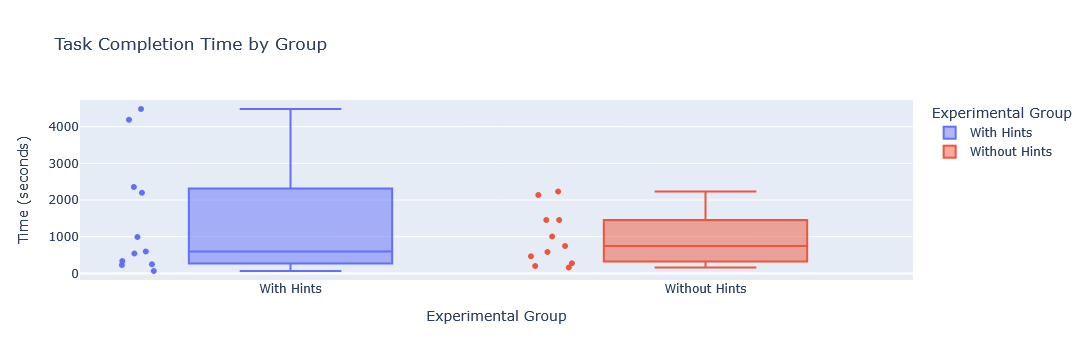

In [16]:
fig = px.box(
    evaluations,
    x="group",
    y="timeInSeconds",
    color="group",
    title="Task Completion Time by Group",
    labels={"timeInSeconds": "Time (seconds)", "group": "Experimental Group"},
    points="all" 
)
fig.show()

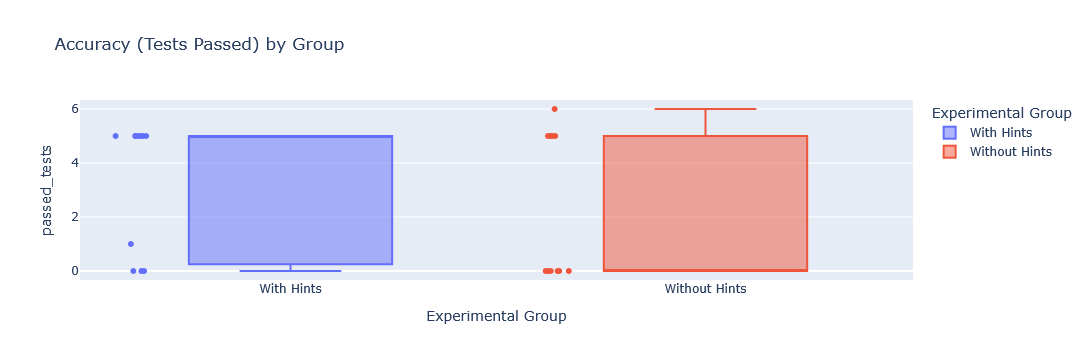

In [18]:
fig = px.box(
    evaluations,
    x="group",
    y="passed_tests",
    color="group",
    title="Accuracy (Tests Passed) by Group",
    labels={"accuracy": "Unit Tests Passed", "group": "Experimental Group"},
    points="all"
)
fig.show()

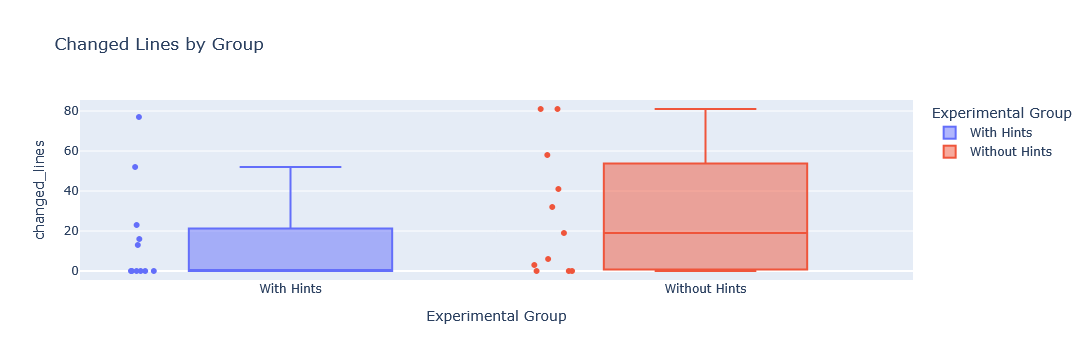

In [21]:
fig = px.box(
    evaluations,
    x="group",
    y="changed_lines",
    color="group",
    title="Changed Lines by Group",
    labels={"survivalRate": "Survival Rate (0-1)", "group": "Experimental Group"},
    points="all"
)
fig.show()

In [23]:
summary = evaluations.groupby("group")[["timeInSeconds", "passed_tests", "changed_lines"]].agg(["mean", "std", "median", "count"])
summary.round(2)

timeInSeconds                       passed_tests               \
                       mean      std median count         mean   std median   
group                                                                         
With Hints          1474.82  1610.78  594.0    11         3.27  2.41    5.0   
Without Hints        974.91   749.76  750.0    11         2.36  2.73    0.0   

                    changed_lines                      
              count          mean    std median count  
group                                                  
With Hints       11         16.45  25.71    0.0    11  
Without Hints    11         29.18  31.98   19.0    11